In [75]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [76]:
# Changes the distribution data to normal distribution

In [77]:
# Why convert to normal distribution?
# some ml algos like linear regression,logistic regression, etc perform 
# better with normally distributed data

In [78]:
# we are learning function transformer

In [79]:
# We can also use our own function to transform the data

In [80]:
# for right skewed data, log transform works the best

In [81]:
# X^2 function is used for left skewed data

In [82]:
# sqrt is not much used 

In [83]:
!pip install scipy

In [84]:
import scipy.stats as stats 
from sklearn.model_selection import train_test_split as tts

In [85]:
from sklearn.metrics import accuracy_score

In [86]:
from sklearn.model_selection import cross_val_score

In [87]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [88]:
df = pd.read_csv('train.csv')

In [89]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [90]:
df = df[['Age','Fare', 'Survived']]

In [91]:
df.head(3)

,Age,Fare,Survived
0,22.0,7.2500,0
1,38.0,71.2833,1
2,26.0,7.9250,1


In [108]:
df.shape

(891, 3)

In [92]:
X=df.drop(columns=['Survived'])

In [109]:
X.shape

(891, 2)

In [93]:
y=df['Survived']

In [110]:
y.shape

(891,)

In [94]:
X

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
886,27.0,13.0000
887,19.0,30.0000
888,NaN,23.4500
889,26.0,30.0000


In [95]:
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [96]:
X_train,X_test,y_train,y_test=tts(X,y,test_size=0.2,random_state=42)

In [111]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 2)
(179, 2)
(712,)
(179,)


<Figure size 2000x1000 with 0 Axes>

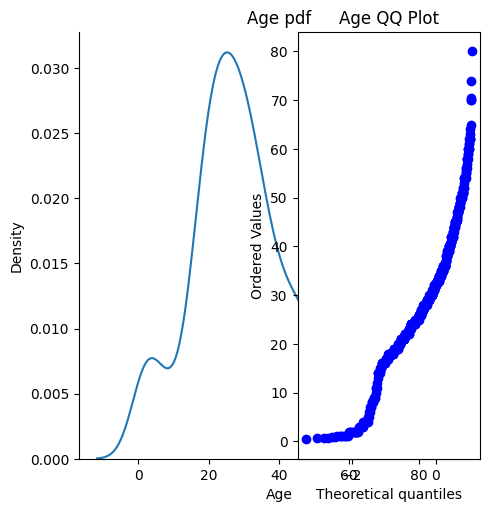

In [97]:
plt.figure(figsize=(20,10))
# plt.subplot(121)
sns.displot(X_train['Age'], kind='kde')
plt.title('Age pdf')
plt.subplot(122)
stats.probplot(X_train['Age'], dist='norm',plot=plt)
plt.title('Age QQ Plot')
plt.show()

<Figure size 2000x1000 with 0 Axes>

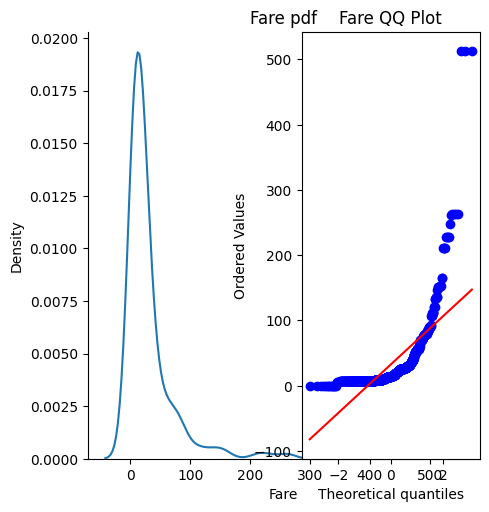

In [98]:
plt.figure(figsize=(20,10))
# plt.subplot(121)
sns.displot(X_train['Fare'], kind='kde')
plt.title('Fare pdf')
plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm',plot=plt)
plt.title('Fare QQ Plot')
plt.show()

In [112]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 2)
(179, 2)
(712,)
(179,)


In [99]:
trf = FunctionTransformer(func=np.log1p)

In [114]:
X_train.shape

(712, 2)

In [100]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf=trf.transform(X_test)

In [113]:
print(X_train_trf.shape)
print(X_test_trf.shape)
print(y_train.shape)
print(y_test.shape)

(179, 2)
(179, 2)
(712,)
(179,)


In [101]:
X_train_trf.isnull().sum()

Age     140
Fare      0
dtype: int64

In [102]:
from sklearn.impute import SimpleImputer

In [103]:
si = SimpleImputer()

In [104]:
X_train_trf = si.fit_transform(X_test_trf)

In [105]:
X_train_trf.shape

(179, 2)

In [106]:
y_train.shape

(712,)

In [107]:
clf = LogisticRegression()
clf2=DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
clf2.fit(X_train_trf,y_train)
y_pred = clf.predict(X_test_trf)
y_pred2 = clf2.predict(X_test_trf)

ValueError: Found input variables with inconsistent numbers of samples: [179, 712]